# Curve curation walkthrough: wildfire × real estate

**Start here.** This notebook shows how the `wildfire_real_estate` curves are built: the house uses the US Forest
Service *Wildfire Risk to Communities* loss figures for a home at each flame-length class, and the warehouse and
office use 0.8× and 0.9× of the house, from CAL FIRE damage inspections that compare building types inside the same
fires.

The companion [`01_runtime_curve_walkthrough.ipynb`](01_runtime_curve_walkthrough.ipynb) calls the curves the way
Hazard would.

Status: **noncanonical proposal** (model v0.1 / docs r1). The cell documents in `docs/cells/wildfire_real_estate/`
are the source of truth; this notebook only reads them.

In [1]:
from pathlib import Path
import json
import re
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display


def find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "docs/cells").is_dir() and (p / "scripts/reference_helpers").is_dir():
            return p
    raise RuntimeError("Run this notebook from inside the Damage_Modeling repository.")


ROOT = find_repo_root()
CELL_ID = "wildfire_real_estate"
PROP = ROOT / "docs/cells" / CELL_ID / "proposed"
ARTIFACT_PATH = PROP / "wildfire_real_estate__model_v0_1__docs_r1__curve_artifact.json"
REG = "wildfire_real_estate__model_v0_1__docs_r1"  # tag of the cell registers (source, claims, tiers, decisions)
OUT = ROOT / "notebooks/wildfire/real_estate/outputs"
OUT.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "scripts/reference_helpers"))

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 220)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

ART = json.loads(ARTIFACT_PATH.read_text())
# Replacement cost new from the Hazard reference profiles r1 (Q3 2025 Dallas prices). Illustration only:
# the artifacts withhold scenario dollars until the consumer qualifies each building value.
BUDGETS_USD = {"RE_RES_SFD_1S_SLAB": 405_000, "RE_IND_WAREHOUSE": 11_000_000, "RE_COM_OFFICE_3S_SLAB": 10_800_000}
NAMES = {"RE_RES_SFD_1S_SLAB": "House", "RE_IND_WAREHOUSE": "Warehouse", "RE_COM_OFFICE_3S_SLAB": "Office",
         "RE_COM_LOWRISE": "Retail (unbound)"}


def table(name: str) -> pd.DataFrame:
    return pd.read_csv(PROP / name)


def save(fig, name: str) -> None:
    fig.savefig(OUT / name, dpi=110, bbox_inches="tight", metadata={"Software": None})


def decision_log(path: Path) -> pd.DataFrame:
    """Decision-log rows: ID, whether JL decided it, and the decision text (shortened)."""
    rows = []
    for line in path.read_text().splitlines():
        if not line.startswith("| D-"):
            continue
        cells = [c.strip() for c in line.strip().strip("|").split(" | ")]
        text = re.sub(r"\*\*", "", cells[1])
        rows.append({"id": cells[0], "status": "JL decided" if "JL decided" in cells[1] else "proposed",
                      "decision": text if len(text) <= 240 else text[:240] + " …"})
    return pd.DataFrame(rows)


print("artifact:", ARTIFACT_PATH.relative_to(ROOT))
print(ART["cell_id"], "|", ART["semantic_damage_model_version"], "|", ART["damage_code_id"],
      "| promotion:", ART["promotion_status"], "| canonical:", ART["canonical_runtime_artifact"])

import derive_wildfire_real_estate_curves as derive

artifact: docs/cells/wildfire_real_estate/proposed/wildfire_real_estate__model_v0_1__docs_r1__curve_artifact.json
wildfire_real_estate | model v0.1 | WILDFIRE_REAL_ESTATE_WRC_FSIM_SCREENING_V0_1 | promotion: proposed | canonical: False


## 1. What the cell is

One pathway (`wildfire_building_exposure`) on Hazard's exact flame-length class state (0 = no event, 1–6 = the six
FSim flame-length classes). The class is categorical: nothing is interpolated between classes. The y-axis is repair
cost ÷ structure replacement cost new.

In [2]:
identity = pd.DataFrame([
    {"field": "cell", "value": ART["cell_id"]},
    {"field": "damage code", "value": ART["damage_code_id"]},
    {"field": "model / docs", "value": f'{ART["semantic_damage_model_version"]} / {ART["documentation_revision"]}'},
    {"field": "lifecycle / promotion", "value": f'{ART["lifecycle_state"]} / {ART["promotion_status"]}'},
    {"field": "canonical runtime artifact", "value": ART["canonical_runtime_artifact"]},
    {"field": "model grade", "value": ART["model_grade"]},
])
display(identity)
units = pd.DataFrame([{k: u.get(k) for k in ("id", "treatment", "denominator")} for u in ART["failure_units"]])
display(units)
pathways = pd.DataFrame([{
    "pathway": p["pathway_id"],
    "axis field": p["hazard_axis"]["preferred_input_field"],
    "unit": p["hazard_axis"]["unit"],
    "valid range": p["hazard_axis"]["valid_range"],
    "selectors": ", ".join(s["field"] for s in p["selector_logic"] if s.get("required")),
    "conditioners": ", ".join(c["field"] for c in p["conditioner_logic"]) or "-",
    "records": len(p["curve_records"]),
} for p in ART["pathways"]])
display(pathways)
print(json.dumps(ART["pathways"][0]["hazard_axis"]["native_class_map"]))
print(ART["pathways"][0]["hazard_axis"]["guardrail"])

,field,value
0,cell,wildfire_real_estate
1,damage code,WILDFIRE_REAL_ESTATE_WRC_FSIM_SCREENING_V0_1
2,model / docs,model v0.1 / docs r1
3,lifecycle / promotion,scaffold / proposed
4,canonical runtime artifact,False
5,model grade,screening_agency_response_function_with_inspection_building_factors


,id,treatment,denominator
0,WFRE_BUILDING_STRUCTURE,primary_nonzero,"structure replacement cost new of the same reference building (no land, contents, site works or depreciation)"
1,WFRE_BUILDING_CONTENTS,withheld,contents value (deferred)


,pathway,axis field,unit,valid range,selectors,conditioners,records
0,wildfire_building_exposure,conditional_flame_length_class_state,source_native_categorical_class,"[0, 6]","reference_building_id, source_wildfire_product_id",-,3


{"lt_2_ft": 1, "gte_2_lt_4_ft": 2, "gte_4_lt_6_ft": 3, "gte_6_lt_8_ft": 4, "gte_8_lt_12_ft": 5, "gte_12_ft": 6}
The class is the flame length of the wildland fire in the cell, not the heat flux, ember load or flame contact at the building; burn probability is frequency and never enters the damage call.


## 2. Evidence register

In [3]:
src = table(f"SOURCE_REGISTER_{REG}.csv")
src["citation"] = src["citation"].str.slice(0, 110)
display(src[["source_id", "citation", "source_role", "evidence_tier", "decision"]])

,source_id,citation,source_role,evidence_tier,decision
0,WFRE-S001,"Dillon, G.K.; Scott, J.H.; Jaffe, M.R.; et al. 2024. Wildfire Risk to Communities: Spatial datasets of landsca",curve_data_carrier;method_definition,T3_engineering_proxy_or_adjacent_empirical,adopt_with_limits
1,WFRE-S002,"CAL FIRE Office of the State Fire Marshal. CAL FIRE Damage Inspection (DINS) Data, master table (CSV export),",independent_verification;building_factor,T3_engineering_proxy_or_adjacent_empirical,adopt_with_limits
2,WFRE-S003,"Dillon, G.K.; Scott, J.H.; Jaffe, M.R.; et al. 2023. Spatial datasets of probabilistic wildfire risk component",axis_definition,T2_public_lab_standard_or_physics,adopt
3,WFRE-S004,"Hazard reference profiles r1 (real-estate CONUS reference candidates), aamani-ai/Hazard_Modeling.",selector_archetype;value_basis,T4_context,adopt
4,WFRE-S005,"Hazard wildfire layer (USFS FSim BP + FLP1-6, 0.25-degree CONUS M1) and its Damage consumer, aamani-ai/Hazard_",axis_bridge;check_input,T4_context,adopt
5,WFRE-S006,"FEMA National Risk Index, December 2025 edition, county building expected annual loss for wildfire (Hazard tea",benchmark_check,T3_engineering_proxy_or_adjacent_empirical,adopt_with_limits
6,WFRE-S007,"Syphard, A.D.; Keeley, J.E. 2019. Factors Associated with Structure Loss in the 2013-2018 California Wildfires",context,T3_engineering_proxy_or_adjacent_empirical,context_only
7,WFRE-S008,"Damage_Modeling repository precedents: wildfire_solar model v1.0 (exact FSim class-state tables), wildfire_win",method_precedent,T4_context,adopt


## 3. The house: USFS response by flame-length class

The USFS gives a percentage loss for a home at each flame-length class, by vegetation type (lifeform). Hazard
supplies no lifeform, so the middle one, **shrub**, is used everywhere; tree and grass are sensitivity cases.

In [4]:
wrc = table(f"WRC_RESPONSE_FUNCTION_TABLE_{REG}.csv")
display(wrc.pivot(index="lifeform", columns="flame_length_class", values="wrc_response_value")
        [["< 2 ft", "2 to < 4 ft", "4 to < 6 ft", "6 to < 8 ft", "8 to < 12 ft", ">= 12 ft"]]
        if ">= 12 ft" in set(wrc.flame_length_class) else wrc.pivot(index="lifeform", columns="state_index", values="wrc_response_value"))

state_index,1,2,3,4,5,6
lifeform,,,,,,
grass,10,25,40,55,70,85
shrub,20,35,50,65,80,95
tree,25,40,55,70,85,100


## 4. Warehouse and office: same-fire comparison from CAL FIRE inspections

CAL FIRE's damage inspections record every building a fire reached. Comparing building types **inside the same
fire** holds the fire, weather and firefighting fixed. Pooled ratios across all fires mostly reflect which fires
hit which buildings, so they are shown only for context.

In [5]:
dins = table(f"DINS_BUILDING_COMPARISON_{REG}.csv")
display(dins[dins.section == "same_fire_ratio"][["subset", "group", "n_buildings", "n_fires", "ratio_to_house", "ratio_p05", "ratio_p95"]])
display(Markdown("Pooled ratios (context only):"))
display(dins[dins.section != "same_fire_ratio"][["subset", "group", "n_buildings", "n_fires", "ratio_to_house"]])
fac = table(f"BUILDING_FACTOR_TABLE_{REG}.csv")
display(fac[["reference_building_id", "factor_on_house_curve", "role", "basis"]])

,subset,group,n_buildings,n_fires,ratio_to_house,ratio_p05,ratio_p95
12,fires with >=1 warehouse_like and >=10 house records,warehouse_like,258,38,0.7938,0.6097,0.9863
13,fires with >=1 office_like and >=10 house records,office_like,204,17,0.9295,0.6588,1.3776


Pooled ratios (context only):

,subset,group,n_buildings,n_fires,ratio_to_house
0,all fires,house,12188,204,1.0000
1,all fires,warehouse_like,363,61,0.3004
2,all fires,office_like,215,24,0.4178
3,fires recording at least 20% no-damage,house,6732,167,1.0000
4,fires recording at least 20% no-damage,warehouse_like,360,58,0.5966
5,fires recording at least 20% no-damage,office_like,211,22,0.8055
6,excluding 2025 Eaton and Palisades fires,house,10360,139,1.0000
7,excluding 2025 Eaton and Palisades fires,warehouse_like,337,52,0.2718
8,excluding 2025 Eaton and Palisades fires,office_like,94,19,0.2772
9,excluding Camp 2018,house,7199,203,1.0000


,reference_building_id,factor_on_house_curve,role,basis
0,RE_RES_SFD_1S_SLAB,1.0,adopted,The USFS response function is defined for a home; used directly
1,RE_IND_WAREHOUSE,0.8,adopted,Same-fire DINS ratio of metal-wall metal-roof commercial buildings to wood-or-vinyl asphalt-roof one-storey houses (0.79; 90% range 0.61-0.99) rounded to on...
2,RE_COM_OFFICE_3S_SLAB,0.9,adopted,Same-fire DINS ratio of stucco/brick/cement multi-storey commercial buildings to the same houses (0.93; 90% range 0.66-1.38) rounded to one decimal
3,RE_IND_WAREHOUSE,0.3,sensitivity,Pooled DINS ratio (all fires together; mix-affected)
4,RE_COM_OFFICE_3S_SLAB,0.4,sensitivity,Pooled DINS ratio (all fires together; mix-affected)
5,RE_IND_WAREHOUSE,1.0,sensitivity,No building difference
6,RE_COM_OFFICE_3S_SLAB,1.0,sensitivity,No building difference


## 5. From the source tables to the curves

`DR(state 0) = 0`; `DR(state k) = factor × USFS_shrub(k) / 100` for k = 1–6. The notebook recomputes the records
from the two source tables with the derive module and compares with the artifact.

,curve_id,factor,states,max |recomputed - artifact|
0,WFRE_RES_WRC_SHRUB,1.0,7,0.0
1,WFRE_IND_WRC_SHRUB_X0_8,0.8,7,0.0
2,WFRE_OFF_WRC_SHRUB_X0_9,0.9,7,0.0


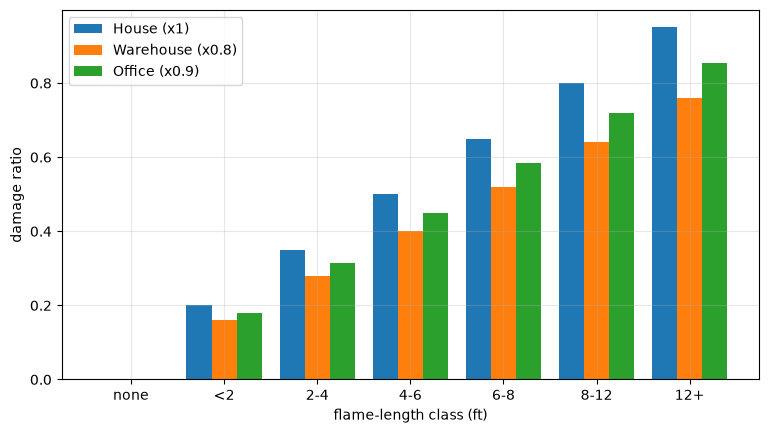

In [6]:
values = derive.wrc()[derive.LIFEFORM]
adopted = derive.factors()
check = []
for r in ART["pathways"][0]["curve_records"]:
    b = r["selector_match"]["reference_building_id"]
    recomputed = derive.curve(values, adopted[b])
    diff = max(abs(a - y) for a, (_, y) in zip(recomputed, r["parameters"]["points"]))
    check.append({"curve_id": r["curve_id"], "factor": adopted[b], "states": len(r["parameters"]["points"]), "max |recomputed - artifact|": diff})
display(pd.DataFrame(check))

fig, ax = plt.subplots(figsize=(9, 4.8))
labels = ["none", "<2", "2-4", "4-6", "6-8", "8-12", "12+"]
width = 0.27
for i, r in enumerate(ART["pathways"][0]["curve_records"]):
    b = r["selector_match"]["reference_building_id"]
    ys = [y for _, y in r["parameters"]["points"]]
    ax.bar(np.arange(7) + (i - 1) * width, ys, width, label=f"{NAMES[b]} (x{adopted[b]:g})")
ax.set_xticks(range(7), labels)
ax.set_xlabel("flame-length class (ft)")
ax.set_ylabel("damage ratio")
ax.legend()
save(fig, "00_curves_by_class.png")
plt.show()

## 6. NRI check

Yearly building loss on Hazard's grid against FEMA's National Risk Index (a check, not a calibration).

In [7]:
nri = table(f"NRI_CHECK_{REG}.csv")
display(nri[["reference_building_id", "variant", "ours_median_pct_per_year", "nri_median_pct_per_year",
             "ours_over_nri_median", "ours_over_nri_national", "spearman_rank_corr", "mean_conditional_dr"]])

,reference_building_id,variant,ours_median_pct_per_year,nri_median_pct_per_year,ours_over_nri_median,ours_over_nri_national,spearman_rank_corr,mean_conditional_dr
0,RE_RES_SFD_1S_SLAB,proposal: shrub with burnable-pixel rate (Hazard production),0.04629,0.02097,2.97,2.01,0.883,0.423
1,RE_RES_SFD_1S_SLAB,shrub with all-pixel rate (Hazard diagnostic),0.03416,0.02097,2.20,1.82,0.885,0.423
2,RE_RES_SFD_1S_SLAB,lifeform tree,0.05192,0.02097,3.34,2.20,0.882,0.473
3,RE_RES_SFD_1S_SLAB,lifeform grass/herbaceous,0.03469,0.02097,2.20,1.64,0.886,0.323
4,RE_IND_WAREHOUSE,proposal: shrub with burnable-pixel rate (Hazard production),0.03703,0.02097,2.38,1.61,0.883,0.338
5,RE_IND_WAREHOUSE,shrub with all-pixel rate (Hazard diagnostic),0.02733,0.02097,1.76,1.45,0.885,0.338
6,RE_IND_WAREHOUSE,lifeform tree,0.04154,0.02097,2.67,1.76,0.882,0.378
7,RE_IND_WAREHOUSE,lifeform grass/herbaceous,0.02775,0.02097,1.76,1.31,0.886,0.258
8,RE_IND_WAREHOUSE,factor 0.3,0.01389,0.02097,0.89,0.60,0.883,0.127
9,RE_IND_WAREHOUSE,factor 1.0,0.04629,0.02097,2.97,2.01,0.883,0.423


## 7. Sensitivity

In [8]:
display(table(f"SENSITIVITY_{REG}.csv"))

,reference_building_id,variant,role,dr_state1,dr_state2,dr_state3,dr_state4,dr_state5,dr_state6
0,RE_RES_SFD_1S_SLAB,reference: shrub with the adopted factor,reference,0.2000,0.3500,0.5000,0.6500,0.8000,0.9500
1,RE_RES_SFD_1S_SLAB,lifeform tree,lifeform,0.2500,0.4000,0.5500,0.7000,0.8500,1.0000
2,RE_RES_SFD_1S_SLAB,lifeform grass/herbaceous,lifeform,0.1000,0.2500,0.4000,0.5500,0.7000,0.8500
3,RE_IND_WAREHOUSE,reference: shrub with the adopted factor,reference,0.1600,0.2800,0.4000,0.5200,0.6400,0.7600
4,RE_IND_WAREHOUSE,lifeform tree,lifeform,0.2000,0.3200,0.4400,0.5600,0.6800,0.8000
5,RE_IND_WAREHOUSE,lifeform grass/herbaceous,lifeform,0.0800,0.2000,0.3200,0.4400,0.5600,0.6800
6,RE_IND_WAREHOUSE,same-fire 90% low (0.61),building_factor,0.1219,0.2134,0.3049,0.3963,0.4878,0.5792
7,RE_IND_WAREHOUSE,same-fire 90% high (0.99; capped at 100%),building_factor,0.1973,0.3452,0.4931,0.6411,0.7890,0.9370
8,RE_IND_WAREHOUSE,factor 0.3 (pooled DINS ratio),building_factor,0.0600,0.1050,0.1500,0.1950,0.2400,0.2850
9,RE_IND_WAREHOUSE,factor 1.0 (same as house),building_factor,0.2000,0.3500,0.5000,0.6500,0.8000,0.9500


## 8. Decisions

In [9]:
log = decision_log(PROP / f"DECISION_LOG_{REG}.md")
display(log.groupby("status").size().rename("decisions").to_frame())
display(log)

,decisions
status,
JL decided,5
proposed,9


,id,status,decision
0,D-WFRE-01,proposed,"One cell, `wildfire_real_estate`, for the three Hazard reference profiles r1 (house `RE_RES_SFD_1S_SLAB`, warehouse `RE_IND_WAREHOUSE`, office `RE_COM_OFFIC..."
1,D-WFRE-02,proposed,"One pathway, `wildfire_building_exposure`: a wildfire reaching the building location, with embers, radiant heat, flame contact and building-to-building spre..."
2,D-WFRE-03,JL decided,JL decided — USFS curve by flame-length class. The house curve is the USFS Wildfire Risk to Communities structure response (WFRE-S001) on Hazard's exact cla...
3,D-WFRE-04,proposed,"Axis = exact FSim conditional flame-length class state 0–6 in `conditional_flame_length_class_state`, with `source_wildfire_product_id = USFS_RDS_2016_0034_..."
4,D-WFRE-05,JL decided,JL decided — shrub lifeform as the default (20/35/50/65/80/95%) for every location; tree (+5 points) and grass (−10 to −15 points) are sensitivity only.
5,D-WFRE-06,JL decided,"JL decided (2026-10-19). The USFS loss value is read as repair cost / structure replacement cost new of the same building (T4 reading, WFRE-C004)."
6,D-WFRE-07,JL decided,"JL decided — building factors from the same-fire CAL FIRE comparison: warehouse = 0.8 × house, office = 0.9 × house, the same factor at every class. Same-fi..."
7,D-WFRE-08,JL decided,"JL decided (2026-10-19). The house uses the USFS home response directly, with no mitigation or defensible-space credit; no conditioner for vegetation cleara..."
8,D-WFRE-09,proposed,State 0 (no event) = 0; states 1–6 are exact table lookups; nothing between classes is evaluated. Six decimals; the table is the governed curve.
9,D-WFRE-10,proposed,"Fail closed: fractional, non-numeric, boolean or out-of-range states → `INVALID_CLASS_STATE`; a burn probability in the damage call → `FREQUENCY_FIELD_NOT_A..."


## 9. Parameter tiers

In [10]:
tiers = pd.DataFrame(ART["parameter_tier_table"])
cols = [c for c in ("parameter", "curve_id", "value", "tier", "status") if c in tiers.columns]
display(tiers[cols])
display(tiers.groupby("tier").size().rename("parameters").to_frame())

,parameter,curve_id,value,tier,status
0,axis_definition,all,exact FSim conditional flame-length class state 0-6 (0 = no event); integers only,T2_public_lab_standard_or_physics,proposed
1,class_identity_wrc_fsim,all,WRC FLP1-6 (30 m WildEST) = FSim FLP1-6 (270 m),T4_placeholder_or_expert_judgment,proposed
2,house_response,WFRE_RES_WRC_SHRUB,0.20/0.35/0.50/0.65/0.80/0.95 for states 1-6,T3_engineering_proxy_or_adjacent_empirical,proposed
3,lifeform_default,all,"shrub (tree +0.05, grass -0.10 to -0.15 as sensitivity)",T4_placeholder_or_expert_judgment,proposed
4,value_reading,all,WRC loss value = repair cost / structure replacement cost new,T4_placeholder_or_expert_judgment,proposed
5,warehouse_factor,WFRE_IND_WRC_SHRUB_X0_8,0.8 x house,T3_engineering_proxy_or_adjacent_empirical,proposed
6,office_factor,WFRE_OFF_WRC_SHRUB_X0_9,0.9 x house,T3_engineering_proxy_or_adjacent_empirical,proposed
7,factor_constant_across_classes,WFRE_IND_*;WFRE_OFF_*,one factor at every class,T4_placeholder_or_expert_judgment,proposed
8,no_event_state,all,state 0 = 0,T2_public_lab_standard_or_physics,proposed
9,tabulation,all,"seven exact states, 6 decimals; no interpolation",T2_public_lab_standard_or_physics,proposed


,parameters
tier,
T2_public_lab_standard_or_physics,3
T3_engineering_proxy_or_adjacent_empirical,3
T4_placeholder_or_expert_judgment,4


## 10. What is still open

- The USFS figures are agency judgment, not repair-cost data; reading them as repair cost ÷ rebuild cost is ours (T4).
- The CAL FIRE commercial buildings are smaller and more mixed than the reference warehouse and office.
- Hazard-side: the fire rate is the burnable-pixel (wildland) rate, not the rate at which fire reaches buildings in
  developed areas; Hazard's generic loader interpolates fractional classes and ignores a burn probability passed in
  the damage call.

In [11]:
cap = ART["capability_declaration"]
rows = []
for pc in cap["pathway_capabilities"]:
    rows.append({"pathway": pc["pathway_id"], "failure-unit DR": pc["failure_unit_scalar_dr"],
                 "scenario loss": pc["scenario_loss_given_value_basis"], "spread": pc["curve_intrinsic_spread"],
                 "withheld units": ", ".join(w["failure_unit_id"] for w in pc.get("withheld_failure_units", []))})
display(pd.DataFrame(rows))
print("Annual and tail metrics:", cap["consumer_annual_metrics"]["status_before_promotion"],
      "(owner:", cap["consumer_annual_metrics"]["computation_owner"] + ")")
print("Promotion gate:", cap["promotion_gate"]["status"])
for item in cap["promotion_gate"]["required_before_canonical_use"]:
    print("  -", item)

,pathway,failure-unit DR,scenario loss,spread,withheld units
0,wildfire_building_exposure,conditional,withheld,not_carried,WFRE_BUILDING_CONTENTS


Annual and tail metrics: withheld_noncanonical_proposal (owner: downstream_consumer)
Promotion gate: blocked
  - owner accepts D-WFRE-01 to D-WFRE-14
  - consumer value qualification of each reference budget (shared with the other real-estate cells)
  - reviewer accepts the agency-response basis, the shrub default and the building factors
  - independent review of the package
